In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving heart_disease_data.csv to heart_disease_data (1).csv


In [ ]:
df = pd.read_csv("heart_disease_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (606, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,48,1,0,130,256,1,0,150,1,0.0,2,2,3,0
1,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
2,44,0,2,118,242,0,1,149,0,0.3,1,1,2,1
3,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
4,56,1,3,120,193,0,0,162,0,1.9,1,0,3,1


In [ ]:
def triangular_membership(x, a, b, c):
    x = np.asarray(x, dtype=float)

    membership = np.zeros_like(x)

    if b != a:
        mask = (x >= a) & (x <= b)
        membership[mask] = (x[mask] - a) / (b - a)

    if c != b:
        mask = (x >= b) & (x <= c)
        membership[mask] = (c - x[mask]) / (c - b)

    membership[x == b] = 1.0

    return membership

In [ ]:
def trapezoidal_membership(x, a, b, c, d):
    x = np.asarray(x, dtype=float)

    membership = np.zeros_like(x)

    if b != a:
        mask = (x >= a) & (x <= b)
        membership[mask] = (x[mask] - a) / (b - a)

    mask = (x >= b) & (x <= c)
    membership[mask] = 1.0

    if d != c:
        mask = (x >= c) & (x <= d)
        membership[mask] = (d - x[mask]) / (d - c)

    return membership

In [ ]:
age_min = df["age"].min()
age_max = df["age"].max()

bp_min = df["trestbps"].min()
bp_max = df["trestbps"].max()

chol_min = df["chol"].min()
chol_max = df["chol"].max()

hr_min = df["thalach"].min()
hr_max = df["thalach"].max()

oldpeak_min = df["oldpeak"].min()
oldpeak_max = df["oldpeak"].max()

print("Ranges loaded successfully.")

Ranges loaded successfully.


In [ ]:
def fuzzify_exang(value):
    if value == 0:
        return {
            "no": 1.0,
            "yes": 0.0
        }
    else:
        return {
            "no": 0.0,
            "yes": 1.0
        }

In [ ]:
def fuzzify_patient(age, trestbps, chol, thalach, oldpeak, exang):

    result = {
        "age": {
            "young": float(trapezoidal_membership(
                np.array([age]),
                age_min, age_min, 35, 45
            )[0]),

            "middle": float(triangular_membership(
                np.array([age]),
                35, 50, 65
            )[0]),

            "old": float(trapezoidal_membership(
                np.array([age]),
                55, 65, age_max, age_max
            )[0])
        },

        "blood_pressure": {
            "normal": float(trapezoidal_membership(
                np.array([trestbps]),
                bp_min, bp_min, 120, 135
            )[0]),

            "high": float(triangular_membership(
                np.array([trestbps]),
                120, 140, 160
            )[0]),

            "very_high": float(trapezoidal_membership(
                np.array([trestbps]),
                145, 160, bp_max, bp_max
            )[0])
        },

        "cholesterol": {
            "normal": float(trapezoidal_membership(
                np.array([chol]),
                chol_min, chol_min, 200, 230
            )[0]),

            "high": float(triangular_membership(
                np.array([chol]),
                200, 240, 280
            )[0]),

            "very_high": float(trapezoidal_membership(
                np.array([chol]),
                260, 280, chol_max, chol_max
            )[0])
        },

        "heart_rate": {
            "low": float(trapezoidal_membership(
                np.array([thalach]),
                hr_min, hr_min, 100, 130
            )[0]),

            "normal": float(triangular_membership(
                np.array([thalach]),
                110, 150, 180
            )[0]),

            "high": float(trapezoidal_membership(
                np.array([thalach]),
                160, 180, hr_max, hr_max
            )[0])
        },

        "oldpeak": {
            "low": float(trapezoidal_membership(
                np.array([oldpeak]),
                oldpeak_min, oldpeak_min, 1.0, 1.5
            )[0]),

            "moderate": float(triangular_membership(
                np.array([oldpeak]),
                1.0, 2.0, 3.0
            )[0]),

            "high": float(trapezoidal_membership(
                np.array([oldpeak]),
                2.5, 3.0, oldpeak_max, oldpeak_max
            )[0])
        },

        "exercise_angina": fuzzify_exang(exang)
    }

    return result

In [ ]:
def rule_and(*memberships):
    return min(memberships)

In [ ]:
strength = rule_and(
    0.80,
    0.60,
    0.70
)

print("Rule firing strength:", strength)

Rule firing strength: 0.6


In [ ]:
rules = [
    {
        "name": "R1",
        "conditions": [
            ("age", "old"),
            ("blood_pressure", "high"),
            ("oldpeak", "high")
        ],
        "risk": "high"
    },

    {
        "name": "R2",
        "conditions": [
            ("age", "old"),
            ("exercise_angina", "yes"),
            ("oldpeak", "high")
        ],
        "risk": "high"
    },

    {
        "name": "R3",
        "conditions": [
            ("blood_pressure", "very_high"),
            ("cholesterol", "very_high")
        ],
        "risk": "high"
    },

    {
        "name": "R4",
        "conditions": [
            ("heart_rate", "low"),
            ("oldpeak", "high")
        ],
        "risk": "high"
    },

    {
        "name": "R5",
        "conditions": [
            ("age", "old"),
            ("heart_rate", "low"),
            ("exercise_angina", "yes")
        ],
        "risk": "high"
    },

    {
        "name": "R6",
        "conditions": [
            ("age", "young"),
            ("blood_pressure", "normal"),
            ("oldpeak", "low")
        ],
        "risk": "low"
    },

    {
        "name": "R7",
        "conditions": [
            ("blood_pressure", "normal"),
            ("cholesterol", "normal"),
            ("oldpeak", "low")
        ],
        "risk": "low"
    },

    {
        "name": "R8",
        "conditions": [
            ("heart_rate", "high"),
            ("oldpeak", "low"),
            ("exercise_angina", "no")
        ],
        "risk": "low"
    },

    {
        "name": "R9",
        "conditions": [
            ("age", "middle"),
            ("blood_pressure", "high"),
            ("oldpeak", "moderate")
        ],
        "risk": "moderate"
    },

    {
        "name": "R10",
        "conditions": [
            ("cholesterol", "high"),
            ("heart_rate", "normal"),
            ("oldpeak", "moderate")
        ],
        "risk": "moderate"
    }
]

print("Number of rules:", len(rules))

Number of rules: 10


In [ ]:
def evaluate_rule(rule, fuzzy_data):

    memberships = []

    for feature, category in rule["conditions"]:
        membership_value = fuzzy_data[feature][category]
        memberships.append(membership_value)

    firing_strength = min(memberships)

    return firing_strength

In [ ]:
patient = df.iloc[0]

fuzzy_data = fuzzify_patient(
    age=patient["age"],
    trestbps=patient["trestbps"],
    chol=patient["chol"],
    thalach=patient["thalach"],
    oldpeak=patient["oldpeak"],
    exang=patient["exang"]
)

print("Patient:")
print(patient)

print("\nFuzzy values:")
print(fuzzy_data)

Patient:
age          48.0
sex           1.0
cp            0.0
trestbps    130.0
chol        256.0
fbs           1.0
restecg       0.0
thalach     150.0
exang         1.0
oldpeak       0.0
slope         2.0
ca            2.0
thal          3.0
target        0.0
Name: 0, dtype: float64

Fuzzy values:
{'age': {'young': 0.0, 'middle': 0.8666666666666667, 'old': 0.0}, 'blood_pressure': {'normal': 0.3333333333333333, 'high': 0.5, 'very_high': 0.0}, 'cholesterol': {'normal': 0.0, 'high': 0.6, 'very_high': 0.0}, 'heart_rate': {'low': 0.0, 'normal': 1.0, 'high': 0.0}, 'oldpeak': {'low': 1.0, 'moderate': 0.0, 'high': 0.0}, 'exercise_angina': {'no': 0.0, 'yes': 1.0}}


In [ ]:
for rule in rules:

    strength = evaluate_rule(
        rule,
        fuzzy_data
    )

    print(
        rule["name"],
        "| Risk:", rule["risk"],
        "| Strength:", round(strength, 3)
    )

R1 | Risk: high | Strength: 0.0
R2 | Risk: high | Strength: 0.0
R3 | Risk: high | Strength: 0.0
R4 | Risk: high | Strength: 0.0
R5 | Risk: high | Strength: 0.0
R6 | Risk: low | Strength: 0.0
R7 | Risk: low | Strength: 0.0
R8 | Risk: low | Strength: 0.0
R9 | Risk: moderate | Strength: 0.0
R10 | Risk: moderate | Strength: 0.0


In [ ]:
for rule in rules:

    strength = evaluate_rule(
        rule,
        fuzzy_data
    )

    if strength > 0:

        print(
            f"{rule['name']} → "
            f"{rule['risk'].upper()} "
            f"(strength = {strength:.3f})"
        )

In [ ]:
for i in range(10):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    activated_rules = []

    for rule in rules:

        strength = evaluate_rule(
            rule,
            fuzzy_data
        )

        if strength > 0:
            activated_rules.append(
                (rule["name"], rule["risk"], strength)
            )

    print("\n-------------------------")
    print("Patient:", i + 1)
    print("Actual target:", patient["target"])

    for name, risk, strength in activated_rules:
        print(
            f"{name} → {risk} "
            f"(strength={strength:.3f})"
        )


-------------------------
Patient: 1
Actual target: 0.0

-------------------------
Patient: 2
Actual target: 0.0
R8 → low (strength=0.050)

-------------------------
Patient: 3
Actual target: 1.0
R6 → low (strength=0.100)

-------------------------
Patient: 4
Actual target: 0.0

-------------------------
Patient: 5
Actual target: 1.0

-------------------------
Patient: 6
Actual target: 0.0
R1 → high (strength=0.800)

-------------------------
Patient: 7
Actual target: 0.0
R9 → moderate (strength=0.133)
R10 → moderate (strength=0.400)

-------------------------
Patient: 8
Actual target: 0.0
R6 → low (strength=0.600)

-------------------------
Patient: 9
Actual target: 1.0

-------------------------
Patient: 10
Actual target: 0.0
R10 → moderate (strength=0.275)


In [ ]:
for i in range(10):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    print("\n==============================")
    print("Patient:", i + 1)
    print("Actual target:", int(patient["target"]))

    print("\nRaw values:")
    print(
        "Age:", patient["age"],
        "| BP:", patient["trestbps"],
        "| Chol:", patient["chol"],
        "| HR:", patient["thalach"],
        "| Oldpeak:", patient["oldpeak"],
        "| Exang:", patient["exang"]
    )

    print("\nFuzzy values:")

    for feature, values in fuzzy_data.items():
        print(f"{feature}: {values}")


Patient: 1
Actual target: 0

Raw values:
Age: 48.0 | BP: 130.0 | Chol: 256.0 | HR: 150.0 | Oldpeak: 0.0 | Exang: 1.0

Fuzzy values:
age: {'young': 0.0, 'middle': 0.8666666666666667, 'old': 0.0}
blood_pressure: {'normal': 0.3333333333333333, 'high': 0.5, 'very_high': 0.0}
cholesterol: {'normal': 0.0, 'high': 0.6, 'very_high': 0.0}
heart_rate: {'low': 0.0, 'normal': 1.0, 'high': 0.0}
oldpeak: {'low': 1.0, 'moderate': 0.0, 'high': 0.0}
exercise_angina: {'no': 0.0, 'yes': 1.0}

Patient: 2
Actual target: 0

Raw values:
Age: 61.0 | BP: 148.0 | Chol: 203.0 | HR: 161.0 | Oldpeak: 0.0 | Exang: 0.0

Fuzzy values:
age: {'young': 0.0, 'middle': 0.26666666666666666, 'old': 0.6}
blood_pressure: {'normal': 0.0, 'high': 0.6, 'very_high': 0.2}
cholesterol: {'normal': 0.9, 'high': 0.075, 'very_high': 0.0}
heart_rate: {'low': 0.0, 'normal': 0.6333333333333333, 'high': 0.05}
oldpeak: {'low': 1.0, 'moderate': 0.0, 'high': 0.0}
exercise_angina: {'no': 1.0, 'yes': 0.0}

Patient: 3
Actual target: 1

Raw valu

In [ ]:
rule_results = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    for rule in rules:

        strength = evaluate_rule(
            rule,
            fuzzy_data
        )

        rule_results.append({
            "patient": i + 1,
            "target": int(patient["target"]),
            "rule": rule["name"],
            "risk": rule["risk"],
            "strength": strength
        })

rule_results_df = pd.DataFrame(rule_results)

rule_results_df.head(20)

,patient,target,rule,risk,strength
0,1,0,R1,high,0.00
1,1,0,R2,high,0.00
2,1,0,R3,high,0.00
3,1,0,R4,high,0.00
4,1,0,R5,high,0.00
5,1,0,R6,low,0.00
6,1,0,R7,low,0.00
7,1,0,R8,low,0.00
8,1,0,R9,moderate,0.00
9,1,0,R10,moderate,0.00


In [ ]:
activation_summary = (
    rule_results_df[
        rule_results_df["strength"] > 0
    ]
    .groupby(["rule", "risk"])
    .size()
    .reset_index(name="activation_count")
)

activation_summary

,rule,risk,activation_count
0,R1,high,30
1,R10,moderate,96
2,R2,high,26
3,R3,high,48
4,R4,high,24
5,R5,high,38
6,R6,low,68
7,R7,low,110
8,R8,low,172
9,R9,moderate,110


In [ ]:
# strongest rule for every patient

In [ ]:
patient_rule_summary = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    rule_strengths = []

    for rule in rules:

        strength = evaluate_rule(
            rule,
            fuzzy_data
        )

        rule_strengths.append({
            "rule": rule["name"],
            "risk": rule["risk"],
            "strength": strength
        })

    strongest_rule = max(
        rule_strengths,
        key=lambda x: x["strength"]
    )

    patient_rule_summary.append({
        "patient": i + 1,
        "target": int(patient["target"]),
        "strongest_rule": strongest_rule["rule"],
        "predicted_risk": strongest_rule["risk"],
        "strength": strongest_rule["strength"]
    })

summary_df = pd.DataFrame(patient_rule_summary)

summary_df.head(10)

,patient,target,strongest_rule,predicted_risk,strength
0,1,0,R1,high,0.000
1,2,0,R8,low,0.050
2,3,1,R6,low,0.100
3,4,0,R1,high,0.000
4,5,1,R1,high,0.000
5,6,0,R1,high,0.800
6,7,0,R10,moderate,0.400
7,8,0,R6,low,0.600
8,9,1,R1,high,0.000
9,10,0,R10,moderate,0.275


In [ ]:
# strong rule distribuctions
summary_df["predicted_risk"].value_counts()

,count
predicted_risk,
high,252
low,230
moderate,124


In [ ]:
# Compare predicted risk with actual target
summary_df["actual_risk"] = summary_df["target"].map({
    0: "low",
    1: "high"
})

comparison = pd.crosstab(
    summary_df["actual_risk"],
    summary_df["predicted_risk"]
)

comparison

predicted_risk,high,low,moderate
actual_risk,,,
high,104,174,52
low,148,56,72


In [ ]:
# Specifically inspect R8
r8_patients = rule_results_df[
    (rule_results_df["rule"] == "R8") &
    (rule_results_df["strength"] > 0)
]

print("R8 activations:", len(r8_patients))

r8_patients["target"].value_counts()

R8 activations: 172


,count
target,
1,140
0,32


In [ ]:
# Inspect R1
r1_patients = rule_results_df[
    (rule_results_df["rule"] == "R1") &
    (rule_results_df["strength"] > 0)
]

print("R1 activations:", len(r1_patients))

print("\nTarget distribution:")
print(r1_patients["target"].value_counts())

R1 activations: 30

Target distribution:
target
0    28
1     2
Name: count, dtype: int64


In [ ]:
# 22 analyzes every rule target base distribuction
rule_analysis = []

for rule_name in rule_results_df["rule"].unique():

    rule_data = rule_results_df[
        (rule_results_df["rule"] == rule_name) &
        (rule_results_df["strength"] > 0)
    ]

    total = len(rule_data)

    if total == 0:
        continue

    target_1 = (rule_data["target"] == 1).sum()
    target_0 = (rule_data["target"] == 0).sum()

    disease_rate = target_1 / total

    rule_analysis.append({
        "rule": rule_name,
        "total_activations": total,
        "target_1": target_1,
        "target_0": target_0,
        "disease_rate": disease_rate
    })

rule_analysis_df = pd.DataFrame(rule_analysis)

rule_analysis_df = rule_analysis_df.sort_values(
    by="disease_rate",
    ascending=False
)

rule_analysis_df

,rule,total_activations,target_1,target_0,disease_rate
5,R6,68,56,12,0.823529
7,R8,172,140,32,0.813953
6,R7,110,82,28,0.745455
9,R10,96,42,54,0.437500
8,R9,110,44,66,0.400000
2,R3,48,18,30,0.375000
4,R5,38,6,32,0.157895
3,R4,24,2,22,0.083333
0,R1,30,2,28,0.066667
1,R2,26,0,26,0.000000


In [ ]:
#  23 how strong the rules are when they activate.
rule_strength_analysis = []

for rule_name in rule_results_df["rule"].unique():

    rule_data = rule_results_df[
        (rule_results_df["rule"] == rule_name) &
        (rule_results_df["strength"] > 0)
    ]

    if len(rule_data) == 0:
        continue

    rule_strength_analysis.append({
        "rule": rule_name,
        "mean_strength": rule_data["strength"].mean(),
        "max_strength": rule_data["strength"].max(),
        "median_strength": rule_data["strength"].median(),
        "activations": len(rule_data)
    })

strength_df = pd.DataFrame(rule_strength_analysis)

strength_df = strength_df.sort_values(
    by="mean_strength",
    ascending=False
)

strength_df

,rule,mean_strength,max_strength,median_strength,activations
2,R3,0.689583,1.000000,0.675000,48
6,R7,0.558182,1.000000,0.466667,110
7,R8,0.543605,1.000000,0.550000,172
0,R1,0.443333,0.800000,0.500000,30
1,R2,0.423077,0.800000,0.400000,26
5,R6,0.352941,1.000000,0.300000,68
4,R5,0.335088,0.900000,0.200000,38
9,R10,0.324826,0.800000,0.300000,96
8,R9,0.308788,0.733333,0.266667,110
3,R4,0.272222,0.633333,0.183333,24


In [ ]:
#  24 individual fuzzy logic analysis
feature_analysis = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    for feature, categories in fuzzy_data.items():

        for category, membership in categories.items():

            if membership > 0:

                feature_analysis.append({
                    "feature": feature,
                    "category": category,
                    "membership": membership,
                    "target": int(patient["target"])
                })

feature_analysis_df = pd.DataFrame(feature_analysis)

feature_analysis_df.head()

,feature,category,membership,target
0,age,middle,0.866667,0
1,blood_pressure,normal,0.333333,0
2,blood_pressure,high,0.500000,0
3,cholesterol,high,0.600000,0
4,heart_rate,normal,1.000000,0


In [ ]:
#  25 category analysis
category_analysis = []

for (feature, category), group in feature_analysis_df.groupby(
    ["feature", "category"]
):

    activated = group[group["membership"] > 0]

    category_analysis.append({
        "feature": feature,
        "category": category,
        "activations": len(activated),
        "target_1": (activated["target"] == 1).sum(),
        "target_0": (activated["target"] == 0).sum(),
        "disease_rate": (activated["target"] == 1).mean(),
        "mean_membership": activated["membership"].mean()
    })

category_analysis_df = pd.DataFrame(category_analysis)

category_analysis_df = category_analysis_df.sort_values(
    by="disease_rate",
    ascending=False
)

category_analysis_df

,feature,category,activations,target_1,target_0,disease_rate,mean_membership
11,heart_rate,high,220,170,50,0.772727,0.547727
2,age,young,112,84,28,0.750000,0.423214
9,exercise_angina,no,408,284,124,0.696078,1.000000
15,oldpeak,low,426,280,146,0.657277,0.914554
7,cholesterol,normal,240,148,92,0.616667,0.716389
6,cholesterol,high,364,212,152,0.582418,0.531044
4,blood_pressure,normal,368,210,158,0.570652,0.732246
13,heart_rate,normal,530,292,238,0.550943,0.563019
0,age,middle,510,278,232,0.545098,0.547712
3,blood_pressure,high,360,192,168,0.533333,0.608056


In [ ]:
# 26 test the membership boundaries against the actual dataset
selected_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "exang"
]

df[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,606.0,54.366337,9.074592,29.0,47.25,55.0,61.00,77.0
trestbps,606.0,131.623762,17.523642,94.0,120.00,130.0,140.00,200.0
chol,606.0,246.264026,51.787898,126.0,211.00,240.0,274.75,564.0
thalach,606.0,149.646865,22.886223,71.0,133.25,153.0,166.00,202.0
oldpeak,606.0,1.039604,1.160115,0.0,0.00,0.8,1.60,6.2
exang,606.0,0.326733,0.469406,0.0,0.00,0.0,1.00,1.0


In [ ]:
# 27
for feature in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    print("\n" + "=" * 50)
    print(feature.upper())
    print("Min    :", df[feature].min())
    print("25%    :", df[feature].quantile(0.25))
    print("Median :", df[feature].median())
    print("75%    :", df[feature].quantile(0.75))
    print("Max    :", df[feature].max())


AGE
Min    : 29
25%    : 47.25
Median : 55.0
75%    : 61.0
Max    : 77

TRESTBPS
Min    : 94
25%    : 120.0
Median : 130.0
75%    : 140.0
Max    : 200

CHOL
Min    : 126
25%    : 211.0
Median : 240.0
75%    : 274.75
Max    : 564

THALACH
Min    : 71
25%    : 133.25
Median : 153.0
75%    : 166.0
Max    : 202

OLDPEAK
Min    : 0.0
25%    : 0.0
Median : 0.8
75%    : 1.6
Max    : 6.2


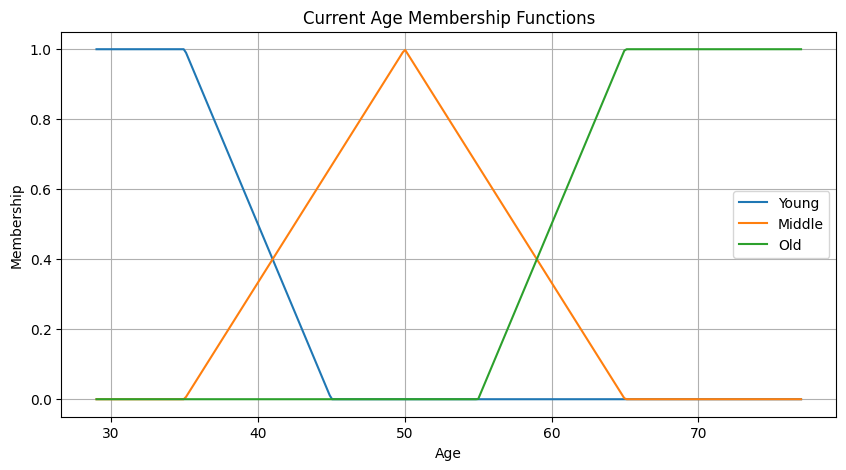

In [ ]:
# 28 visulization membership functions
age_values = np.linspace(age_min, age_max, 300)
bp_values = np.linspace(bp_min, bp_max, 300)
chol_values = np.linspace(chol_min, chol_max, 300)
hr_values = np.linspace(hr_min, hr_max, 300)
oldpeak_values = np.linspace(oldpeak_min, oldpeak_max, 300)

plt.figure(figsize=(10, 5))

plt.plot(
    age_values,
    trapezoidal_membership(age_values, age_min, age_min, 35, 45),
    label="Young"
)

plt.plot(
    age_values,
    triangular_membership(age_values, 35, 50, 65),
    label="Middle"
)

plt.plot(
    age_values,
    trapezoidal_membership(age_values, 55, 65, age_max, age_max),
    label="Old"
)

plt.xlabel("Age")
plt.ylabel("Membership")
plt.title("Current Age Membership Functions")
plt.legend()
plt.grid(True)

plt.show()

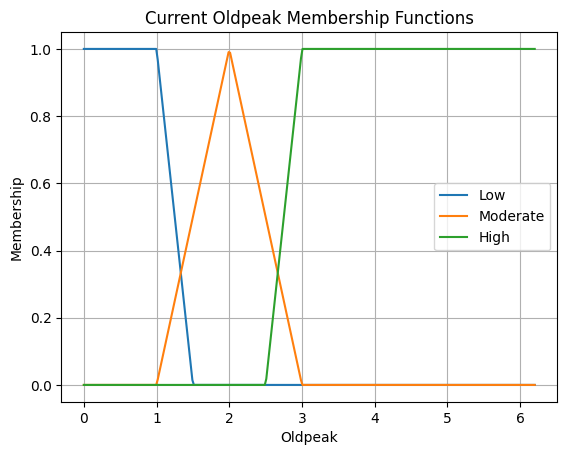

In [ ]:
# 29 plt.figure(figsize=(10, 5))

plt.plot(
    oldpeak_values,
    trapezoidal_membership(
        oldpeak_values,
        oldpeak_min,
        oldpeak_min,
        1.0,
        1.5
    ),
    label="Low"
)

plt.plot(
    oldpeak_values,
    triangular_membership(
        oldpeak_values,
        1.0,
        2.0,
        3.0
    ),
    label="Moderate"
)

plt.plot(
    oldpeak_values,
    trapezoidal_membership(
        oldpeak_values,
        2.5,
        3.0,
        oldpeak_max,
        oldpeak_max
    ),
    label="High"
)

plt.xlabel("Oldpeak")
plt.ylabel("Membership")
plt.title("Current Oldpeak Membership Functions")
plt.legend()
plt.grid(True)

plt.show()

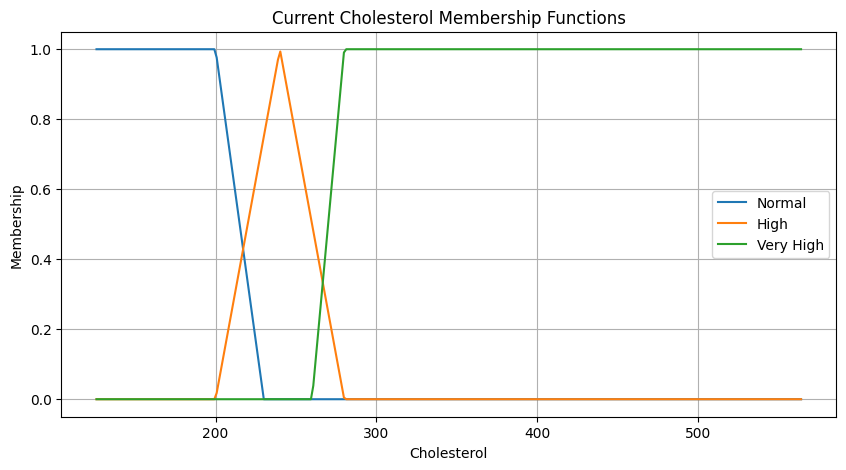

In [ ]:
# 30
plt.figure(figsize=(10, 5))

plt.plot(
    chol_values,
    trapezoidal_membership(
        chol_values,
        chol_min,
        chol_min,
        200,
        230
    ),
    label="Normal"
)

plt.plot(
    chol_values,
    triangular_membership(
        chol_values,
        200,
        240,
        280
    ),
    label="High"
)

plt.plot(
    chol_values,
    trapezoidal_membership(
        chol_values,
        260,
        280,
        chol_max,
        chol_max
    ),
    label="Very High"
)

plt.xlabel("Cholesterol")
plt.ylabel("Membership")
plt.title("Current Cholesterol Membership Functions")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# version v2 testfunction
# revised membership definitions 31
def fuzzify_patient_v2(age, trestbps, chol, thalach, oldpeak, exang):

    fuzzy_data = {}

    # -------------------------
    # AGE
    # -------------------------
    fuzzy_data["age"] = {
        "young": trapezoidal_membership(
            age, age_min, age_min, 35, 45
        ).item(),

        "middle": triangular_membership(
            age, 35, 50, 65
        ).item(),

        "old": trapezoidal_membership(
            age, 55, 65, age_max, age_max
        ).item()
    }

    # -------------------------
    # BLOOD PRESSURE
    # Keep current version for now
    # -------------------------
    fuzzy_data["blood_pressure"] = {
        "normal": trapezoidal_membership(
            trestbps, bp_min, bp_min, 120, 135
        ).item(),

        "high": triangular_membership(
            trestbps, 120, 140, 160
        ).item(),

        "very_high": trapezoidal_membership(
            trestbps, 145, 160, bp_max, bp_max
        ).item()
    }

    # -------------------------
    # CHOLESTEROL - V2
    # -------------------------
    fuzzy_data["cholesterol"] = {
        "normal": trapezoidal_membership(
            chol, chol_min, chol_min, 211, 240
        ).item(),

        "high": triangular_membership(
            chol, 211, 240, 275
        ).item(),

        "very_high": trapezoidal_membership(
            chol, 260, 275, chol_max, chol_max
        ).item()
    }

    # -------------------------
    # HEART RATE
    # Keep current version for now
    # -------------------------
    fuzzy_data["heart_rate"] = {
        "low": trapezoidal_membership(
            thalach, hr_min, hr_min, 100, 130
        ).item(),

        "normal": triangular_membership(
            thalach, 110, 150, 180
        ).item(),

        "high": trapezoidal_membership(
            thalach, 160, 180, hr_max, hr_max
        ).item()
    }

    # -------------------------
    # OLDPEAK - V2
    # -------------------------
    fuzzy_data["oldpeak"] = {
        "low": trapezoidal_membership(
            oldpeak, 0, 0, 0.5, 1.0
        ).item(),

        "moderate": triangular_membership(
            oldpeak, 0.5, 1.2, 2.0
        ).item(),

        "high": trapezoidal_membership(
            oldpeak, 1.5, 2.5, oldpeak_max, oldpeak_max
        ).item()
    }

    # -------------------------
    # EXERCISE ANGINA
    # -------------------------
    fuzzy_data["exercise_angina"] = fuzzify_exang(exang)

    return fuzzy_data


In [ ]:
# 32
for i in range(10):

    patient = df.iloc[i]

    fuzzy_v2 = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    print("\n" + "=" * 60)
    print(f"Patient {i+1} | Target = {int(patient['target'])}")

    print("Age:", fuzzy_v2["age"])
    print("Blood Pressure:", fuzzy_v2["blood_pressure"])
    print("Cholesterol:", fuzzy_v2["cholesterol"])
    print("Heart Rate:", fuzzy_v2["heart_rate"])
    print("Oldpeak:", fuzzy_v2["oldpeak"])
    print("Exercise Angina:", fuzzy_v2["exercise_angina"])


Patient 1 | Target = 0
Age: {'young': 0.0, 'middle': 0.8666666666666667, 'old': 0.0}
Blood Pressure: {'normal': 0.3333333333333333, 'high': 0.5, 'very_high': 0.0}
Cholesterol: {'normal': 0.0, 'high': 0.5428571428571428, 'very_high': 0.0}
Heart Rate: {'low': 0.0, 'normal': 1.0, 'high': 0.0}
Oldpeak: {'low': 1.0, 'moderate': 0.0, 'high': 0.0}
Exercise Angina: {'no': 0.0, 'yes': 1.0}

Patient 2 | Target = 0
Age: {'young': 0.0, 'middle': 0.26666666666666666, 'old': 0.6}
Blood Pressure: {'normal': 0.0, 'high': 0.6, 'very_high': 0.2}
Cholesterol: {'normal': 1.0, 'high': 0.0, 'very_high': 0.0}
Heart Rate: {'low': 0.0, 'normal': 0.6333333333333333, 'high': 0.05}
Oldpeak: {'low': 1.0, 'moderate': 0.0, 'high': 0.0}
Exercise Angina: {'no': 1.0, 'yes': 0.0}

Patient 3 | Target = 1
Age: {'young': 0.1, 'middle': 0.6, 'old': 0.0}
Blood Pressure: {'normal': 1.0, 'high': 0.0, 'very_high': 0.0}
Cholesterol: {'normal': 0.0, 'high': 0.9428571428571428, 'very_high': 0.0}
Heart Rate: {'low': 0.0, 'normal':

In [ ]:
# 33 Recalculate the category analysis using V2
feature_analysis_v2 = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    for feature, categories in fuzzy_data.items():

        for category, membership in categories.items():

            if membership > 0:

                feature_analysis_v2.append({
                    "feature": feature,
                    "category": category,
                    "membership": membership,
                    "target": int(patient["target"])
                })

feature_analysis_v2_df = pd.DataFrame(feature_analysis_v2)

feature_analysis_v2_df.head()

,feature,category,membership,target
0,age,middle,0.866667,0
1,blood_pressure,normal,0.333333,0
2,blood_pressure,high,0.500000,0
3,cholesterol,high,0.542857,0
4,heart_rate,normal,1.000000,0


In [ ]:
# 34
category_analysis_v2 = []

for (feature, category), group in feature_analysis_v2_df.groupby(
    ["feature", "category"]
):

    category_analysis_v2.append({
        "feature": feature,
        "category": category,
        "activations": len(group),
        "target_1": (group["target"] == 1).sum(),
        "target_0": (group["target"] == 0).sum(),
        "disease_rate": (group["target"] == 1).mean(),
        "mean_membership": group["membership"].mean()
    })

category_analysis_v2_df = pd.DataFrame(category_analysis_v2)

category_analysis_v2_df = category_analysis_v2_df.sort_values(
    by="disease_rate",
    ascending=False
)

category_analysis_v2_df

,feature,category,activations,target_1,target_0,disease_rate,mean_membership
11,heart_rate,high,220,170,50,0.772727,0.547727
2,age,young,112,84,28,0.750000,0.423214
15,oldpeak,low,332,240,92,0.722892,0.919277
9,exercise_angina,no,408,284,124,0.696078,1.000000
7,cholesterol,normal,296,178,118,0.601351,0.756524
4,blood_pressure,normal,368,210,158,0.570652,0.732246
6,cholesterol,high,298,166,132,0.557047,0.524488
13,heart_rate,normal,530,292,238,0.550943,0.563019
0,age,middle,510,278,232,0.545098,0.547712
3,blood_pressure,high,360,192,168,0.533333,0.608056


In [ ]:
# compare v1 to v2
comparison_v1_v2 = category_analysis_df[
    ["feature", "category", "activations", "disease_rate", "mean_membership"]
].copy()

comparison_v1_v2 = comparison_v1_v2.rename(columns={
    "activations": "v1_activations",
    "disease_rate": "v1_disease_rate",
    "mean_membership": "v1_mean_membership"
})

comparison_v1_v2 = comparison_v1_v2.merge(
    category_analysis_v2_df[
        ["feature", "category", "activations", "disease_rate", "mean_membership"]
    ],
    on=["feature", "category"],
    suffixes=("", "_v2")
)

comparison_v1_v2

,feature,category,v1_activations,v1_disease_rate,v1_mean_membership,activations,disease_rate,mean_membership
0,heart_rate,high,220,0.772727,0.547727,220,0.772727,0.547727
1,age,young,112,0.750000,0.423214,112,0.750000,0.423214
2,exercise_angina,no,408,0.696078,1.000000,408,0.696078,1.000000
3,oldpeak,low,426,0.657277,0.914554,332,0.722892,0.919277
4,cholesterol,normal,240,0.616667,0.716389,296,0.601351,0.756524
5,cholesterol,high,364,0.582418,0.531044,298,0.557047,0.524488
6,blood_pressure,normal,368,0.570652,0.732246,368,0.570652,0.732246
7,heart_rate,normal,530,0.550943,0.563019,530,0.550943,0.563019
8,age,middle,510,0.545098,0.547712,510,0.545098,0.547712
9,blood_pressure,high,360,0.533333,0.608056,360,0.533333,0.608056


In [ ]:
# V2 + current rules 35
rule_results_v2 = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    for rule in rules:

        strength = evaluate_rule(rule, fuzzy_data)

        rule_results_v2.append({
            "patient": i + 1,
            "target": int(patient["target"]),
            "rule": rule["name"],
            "risk": rule["risk"],
            "strength": strength
        })

rule_results_v2_df = pd.DataFrame(rule_results_v2)

print("V2 rule testing completed.")
print("Rows:", len(rule_results_v2_df))

V2 rule testing completed.
Rows: 6060


In [ ]:
# Analyze V2 rule activation 36
v2_rule_activation = []

for rule_name in rule_results_v2_df["rule"].unique():

    rule_data = rule_results_v2_df[
        (rule_results_v2_df["rule"] == rule_name) &
        (rule_results_v2_df["strength"] > 0)
    ]

    v2_rule_activation.append({
        "rule": rule_name,
        "risk": rules[[r["name"] for r in rules].index(rule_name)]["risk"],
        "activations": len(rule_data),
        "mean_strength": rule_data["strength"].mean(),
        "max_strength": rule_data["strength"].max()
    })

v2_rule_activation_df = pd.DataFrame(v2_rule_activation)

v2_rule_activation_df.sort_values(
    by="activations",
    ascending=False
)

,rule,risk,activations,mean_strength,max_strength
7,R8,low,148,0.550676,1.000000
8,R9,moderate,108,0.349802,0.733333
6,R7,low,106,0.622468,1.000000
9,R10,moderate,86,0.308697,0.800000
0,R1,high,70,0.427143,0.800000
5,R6,low,62,0.341935,1.000000
3,R4,high,54,0.361728,0.700000
1,R2,high,52,0.426923,1.000000
2,R3,high,48,0.727778,1.000000
4,R5,high,38,0.335088,0.900000


In [ ]:
# 37 V2 disease association of each rule
v2_rule_analysis = []

for rule_name in rule_results_v2_df["rule"].unique():

    rule_data = rule_results_v2_df[
        (rule_results_v2_df["rule"] == rule_name) &
        (rule_results_v2_df["strength"] > 0)
    ]

    if len(rule_data) == 0:
        continue

    v2_rule_analysis.append({
        "rule": rule_name,
        "risk": rule_data["risk"].iloc[0],
        "activations": len(rule_data),
        "target_1": (rule_data["target"] == 1).sum(),
        "target_0": (rule_data["target"] == 0).sum(),
        "disease_rate": (rule_data["target"] == 1).mean(),
        "mean_strength": rule_data["strength"].mean()
    })

v2_rule_analysis_df = pd.DataFrame(v2_rule_analysis)

v2_rule_analysis_df = v2_rule_analysis_df.sort_values(
    by="disease_rate",
    ascending=False
)

v2_rule_analysis_df

,rule,risk,activations,target_1,target_0,disease_rate,mean_strength
5,R6,low,62,52,10,0.838710,0.341935
7,R8,low,148,124,24,0.837838,0.550676
6,R7,low,106,84,22,0.792453,0.622468
9,R10,moderate,86,46,40,0.534884,0.308697
8,R9,moderate,108,52,56,0.481481,0.349802
2,R3,high,48,18,30,0.375000,0.727778
0,R1,high,70,14,56,0.200000,0.427143
4,R5,high,38,6,32,0.157895,0.335088
3,R4,high,54,6,48,0.111111,0.361728
1,R2,high,52,2,50,0.038462,0.426923


In [ ]:
# 38 new candidate rule base
final_rules = [

    # =========================
    # HIGH RISK RULES
    # =========================

    {
        "name": "H1",
        "conditions": [
            ("heart_rate", "high"),
            ("age", "young")
        ],
        "risk": "high"
    },

    {
        "name": "H2",
        "conditions": [
            ("heart_rate", "high"),
            ("oldpeak", "moderate")
        ],
        "risk": "high"
    },

    {
        "name": "H3",
        "conditions": [
            ("heart_rate", "high"),
            ("exercise_angina", "no")
        ],
        "risk": "high"
    },

    {
        "name": "H4",
        "conditions": [
            ("age", "young"),
            ("oldpeak", "low"),
            ("exercise_angina", "no")
        ],
        "risk": "high"
    },

    {
        "name": "H5",
        "conditions": [
            ("age", "old"),
            ("cholesterol", "very_high"),
            ("exercise_angina", "no")
        ],
        "risk": "high"
    },

    {
        "name": "H6",
        "conditions": [
            ("cholesterol", "very_high"),
            ("heart_rate", "high")
        ],
        "risk": "high"
    },

    {
        "name": "H7",
        "conditions": [
            ("heart_rate", "normal"),
            ("oldpeak", "moderate"),
            ("cholesterol", "high")
        ],
        "risk": "high"
    },


    # =========================
    # MODERATE RISK RULES
    # =========================

    {
        "name": "M1",
        "conditions": [
            ("age", "middle"),
            ("blood_pressure", "high"),
            ("oldpeak", "moderate")
        ],
        "risk": "moderate"
    },

    {
        "name": "M2",
        "conditions": [
            ("cholesterol", "high"),
            ("heart_rate", "normal"),
            ("oldpeak", "moderate")
        ],
        "risk": "moderate"
    },

    {
        "name": "M3",
        "conditions": [
            ("age", "old"),
            ("blood_pressure", "high")
        ],
        "risk": "moderate"
    },

    {
        "name": "M4",
        "conditions": [
            ("cholesterol", "very_high"),
            ("blood_pressure", "high")
        ],
        "risk": "moderate"
    },

    {
        "name": "M5",
        "conditions": [
            ("age", "middle"),
            ("oldpeak", "moderate"),
            ("heart_rate", "normal")
        ],
        "risk": "moderate"
    },


    # =========================
    # LOW RISK RULES
    # =========================

    {
        "name": "L1",
        "conditions": [
            ("blood_pressure", "normal"),
            ("cholesterol", "normal"),
            ("oldpeak", "low"),
            ("heart_rate", "normal")
        ],
        "risk": "low"
    },

    {
        "name": "L2",
        "conditions": [
            ("age", "middle"),
            ("blood_pressure", "normal"),
            ("oldpeak", "low"),
            ("exercise_angina", "yes")
        ],
        "risk": "low"
    },

    {
        "name": "L3",
        "conditions": [
            ("blood_pressure", "normal"),
            ("cholesterol", "normal"),
            ("heart_rate", "normal"),
            ("oldpeak", "low")
        ],
        "risk": "low"
    },

    {
        "name": "L4",
        "conditions": [
            ("age", "old"),
            ("blood_pressure", "normal"),
            ("cholesterol", "normal"),
            ("oldpeak", "low")
        ],
        "risk": "low"
    }
]

print("Final candidate rules:", len(final_rules))

Final candidate rules: 16


In [ ]:
# 39 Test the 16 candidate rules
final_rule_results = []

for i in range(len(df)):

    patient = df.iloc[i]

    fuzzy_data = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    for rule in final_rules:

        strength = evaluate_rule(rule, fuzzy_data)

        final_rule_results.append({
            "patient": i + 1,
            "target": int(patient["target"]),
            "rule": rule["name"],
            "risk": rule["risk"],
            "strength": strength
        })

final_rule_results_df = pd.DataFrame(final_rule_results)

print("Candidate rule testing completed.")
print("Total evaluations:", len(final_rule_results_df))

Candidate rule testing completed.
Total evaluations: 9696


In [ ]:
# 40 Candidate rule quality
candidate_analysis = []

for rule_name in final_rule_results_df["rule"].unique():

    rule_data = final_rule_results_df[
        (final_rule_results_df["rule"] == rule_name) &
        (final_rule_results_df["strength"] > 0)
    ]

    if len(rule_data) == 0:
        candidate_analysis.append({
            "rule": rule_name,
            "risk": final_rule_results_df[
                final_rule_results_df["rule"] == rule_name
            ]["risk"].iloc[0],
            "activations": 0,
            "target_1": 0,
            "target_0": 0,
            "disease_rate": np.nan,
            "mean_strength": np.nan
        })
        continue

    candidate_analysis.append({
        "rule": rule_name,
        "risk": rule_data["risk"].iloc[0],
        "activations": len(rule_data),
        "target_1": (rule_data["target"] == 1).sum(),
        "target_0": (rule_data["target"] == 0).sum(),
        "disease_rate": (rule_data["target"] == 1).mean(),
        "mean_strength": rule_data["strength"].mean()
    })

candidate_analysis_df = pd.DataFrame(candidate_analysis)

candidate_analysis_df.sort_values(
    by="disease_rate",
    ascending=False
)

,rule,risk,activations,target_1,target_0,disease_rate,mean_strength
0,H1,high,78,72,6,0.923077,0.392308
3,H4,high,72,64,8,0.888889,0.397222
2,H3,high,192,156,36,0.812500,0.556771
14,L3,low,88,68,20,0.772727,0.360051
12,L1,low,88,68,20,0.772727,0.360051
1,H2,high,64,46,18,0.718750,0.374554
5,H6,high,64,46,18,0.718750,0.435417
15,L4,low,32,20,12,0.625000,0.410201
13,L2,low,28,16,12,0.571429,0.380952
8,M2,moderate,86,46,40,0.534884,0.308697


In [ ]:
#  41 — find promising LOW combinations
from itertools import combinations

candidate_low_rules = []

features_for_low = [
    "age",
    "blood_pressure",
    "cholesterol",
    "heart_rate",
    "oldpeak",
    "exercise_angina"
]

categories_for_low = {
    "age": ["young", "middle", "old"],
    "blood_pressure": ["normal", "high", "very_high"],
    "cholesterol": ["normal", "high", "very_high"],
    "heart_rate": ["low", "normal", "high"],
    "oldpeak": ["low", "moderate", "high"],
    "exercise_angina": ["no", "yes"]
}

for feature_pair in combinations(features_for_low, 2):

    f1, f2 = feature_pair

    for c1 in categories_for_low[f1]:
        for c2 in categories_for_low[f2]:

            matched = []

            for i in range(len(df)):

                patient = df.iloc[i]

                fuzzy = fuzzify_patient_v2(
                    age=patient["age"],
                    trestbps=patient["trestbps"],
                    chol=patient["chol"],
                    thalach=patient["thalach"],
                    oldpeak=patient["oldpeak"],
                    exang=patient["exang"]
                )

                strength = min(
                    fuzzy[f1][c1],
                    fuzzy[f2][c2]
                )

                if strength > 0:
                    matched.append({
                        "target": int(patient["target"]),
                        "strength": strength
                    })

            if len(matched) >= 10:

                matched_df = pd.DataFrame(matched)

                candidate_low_rules.append({
                    "condition_1": f"{f1}={c1}",
                    "condition_2": f"{f2}={c2}",
                    "activations": len(matched_df),
                    "disease_rate": matched_df["target"].mean(),
                    "mean_strength": matched_df["strength"].mean()
                })

low_candidates_df = pd.DataFrame(candidate_low_rules)

low_candidates_df.sort_values(
    by=["disease_rate", "activations"],
    ascending=[True, False]
).head(15)

,condition_1,condition_2,activations,disease_rate,mean_strength
117,oldpeak=high,exercise_angina=yes,90,0.044444,0.720000
55,blood_pressure=very_high,heart_rate=low,28,0.071429,0.385714
99,heart_rate=low,oldpeak=high,54,0.111111,0.361728
72,blood_pressure=very_high,exercise_angina=yes,34,0.117647,0.811765
90,cholesterol=very_high,oldpeak=high,62,0.129032,0.574194
107,heart_rate=low,exercise_angina=yes,70,0.142857,0.492381
79,cholesterol=very_high,heart_rate=low,52,0.153846,0.480769
96,cholesterol=very_high,exercise_angina=yes,82,0.170732,0.878049
39,age=old,exercise_angina=yes,112,0.178571,0.558929
70,blood_pressure=high,exercise_angina=yes,120,0.216667,0.617500


In [ ]:
final_rules = [
    # HIGH RISK
    {"name": "H1", "conditions": [("heart_rate", "high"), ("age", "young")], "risk": "high"},
    {"name": "H2", "conditions": [("heart_rate", "high"), ("oldpeak", "moderate")], "risk": "high"},
    {"name": "H3", "conditions": [("heart_rate", "high"), ("exercise_angina", "no")], "risk": "high"},
    {"name": "H4", "conditions": [("age", "young"), ("oldpeak", "low"), ("exercise_angina", "no")], "risk": "high"},
    {"name": "H5", "conditions": [("cholesterol", "very_high"), ("heart_rate", "high")], "risk": "high"},

    # MODERATE RISK
    {"name": "M1", "conditions": [("age", "middle"), ("blood_pressure", "high"), ("oldpeak", "moderate")], "risk": "moderate"},
    {"name": "M2", "conditions": [("cholesterol", "high"), ("heart_rate", "normal"), ("oldpeak", "moderate")], "risk": "moderate"},
    {"name": "M3", "conditions": [("age", "middle"), ("oldpeak", "moderate"), ("heart_rate", "normal")], "risk": "moderate"},

    # LOW RISK
    {"name": "L1", "conditions": [("oldpeak", "high"), ("exercise_angina", "yes")], "risk": "low"},
    {"name": "L2", "conditions": [("heart_rate", "low"), ("oldpeak", "high")], "risk": "low"},
    {"name": "L3", "conditions": [("cholesterol", "very_high"), ("exercise_angina", "yes")], "risk": "low"},
    {"name": "L4", "conditions": [("age", "old"), ("exercise_angina", "yes")], "risk": "low"}
]

print("Final rule count:", len(final_rules))

for rule in final_rules:
    print(rule)

Final rule count: 12
{'name': 'H1', 'conditions': [('heart_rate', 'high'), ('age', 'young')], 'risk': 'high'}
{'name': 'H2', 'conditions': [('heart_rate', 'high'), ('oldpeak', 'moderate')], 'risk': 'high'}
{'name': 'H3', 'conditions': [('heart_rate', 'high'), ('exercise_angina', 'no')], 'risk': 'high'}
{'name': 'H4', 'conditions': [('age', 'young'), ('oldpeak', 'low'), ('exercise_angina', 'no')], 'risk': 'high'}
{'name': 'H5', 'conditions': [('cholesterol', 'very_high'), ('heart_rate', 'high')], 'risk': 'high'}
{'name': 'M1', 'conditions': [('age', 'middle'), ('blood_pressure', 'high'), ('oldpeak', 'moderate')], 'risk': 'moderate'}
{'name': 'M2', 'conditions': [('cholesterol', 'high'), ('heart_rate', 'normal'), ('oldpeak', 'moderate')], 'risk': 'moderate'}
{'name': 'M3', 'conditions': [('age', 'middle'), ('oldpeak', 'moderate'), ('heart_rate', 'normal')], 'risk': 'moderate'}
{'name': 'L1', 'conditions': [('oldpeak', 'high'), ('exercise_angina', 'yes')], 'risk': 'low'}
{'name': 'L2', 'c

In [ ]:
# Fuzzy interface engine
# Test multiple patients
test_patients = [0, 2, 4, 7, 8]

for patient_index in test_patients:

    patient = df.iloc[patient_index]

    fuzzy_patient = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    rule_results = evaluate_all_rules(
        fuzzy_patient,
        final_rules
    )

    print("\n" + "=" * 60)
    print(f"Patient index: {patient_index}")
    print(f"Actual target: {int(patient['target'])}")

    print("\nRules that fired:")

    fired_rules = rule_results[
        rule_results["firing_strength"] > 0
    ]

    if len(fired_rules) == 0:
        print("No rules fired.")

    else:
        print(fired_rules.to_string(index=False))


Patient index: 0
Actual target: 0

Rules that fired:
No rules fired.

Patient index: 2
Actual target: 1

Rules that fired:
rule risk  firing_strength
  H4 high              0.1

Patient index: 4
Actual target: 1

Rules that fired:
rule     risk  firing_strength
  H2     high            0.100
  H3     high            0.100
  M3 moderate            0.125

Patient index: 7
Actual target: 0

Rules that fired:
rule risk  firing_strength
  L3  low              1.0

Patient index: 8
Actual target: 1

Rules that fired:
No rules fired.


In [ ]:
# aggragation engine
def aggregate_risk(rule_results):
    """
    Aggregate rule firing strengths by risk category.
    Uses MAX aggregation.
    """

    high_strength = rule_results[
        rule_results["risk"] == "high"
    ]["firing_strength"].max()

    moderate_strength = rule_results[
        rule_results["risk"] == "moderate"
    ]["firing_strength"].max()

    low_strength = rule_results[
        rule_results["risk"] == "low"
    ]["firing_strength"].max()

    # Replace NaN with 0
    high_strength = 0.0 if pd.isna(high_strength) else high_strength
    moderate_strength = 0.0 if pd.isna(moderate_strength) else moderate_strength
    low_strength = 0.0 if pd.isna(low_strength) else low_strength

    return {
        "high": high_strength,
        "moderate": moderate_strength,
        "low": low_strength
    }


# Test using Patient 4
patient = df.iloc[4]

fuzzy_patient = fuzzify_patient_v2(
    age=patient["age"],
    trestbps=patient["trestbps"],
    chol=patient["chol"],
    thalach=patient["thalach"],
    oldpeak=patient["oldpeak"],
    exang=patient["exang"]
)

rule_results = evaluate_all_rules(
    fuzzy_patient,
    final_rules
)

aggregated_risk = aggregate_risk(rule_results)

print("Actual target:", int(patient["target"]))
print("Aggregated fuzzy risk:")
print(aggregated_risk)

Actual target: 1
Aggregated fuzzy risk:
{'high': 0.1, 'moderate': 0.1250000000000001, 'low': 0.0}


In [ ]:
# Defuzzification
def defuzzify_risk(aggregated_risk):
    """
    Convert aggregated fuzzy risk strengths
    into a numerical risk score from 0 to 100.
    """

    risk_values = {
        "low": 25,
        "moderate": 50,
        "high": 75
    }

    low = aggregated_risk["low"]
    moderate = aggregated_risk["moderate"]
    high = aggregated_risk["high"]

    total_strength = low + moderate + high

    # No rule fired
    if total_strength == 0:
        return None

    risk_score = (
        (low * risk_values["low"]) +
        (moderate * risk_values["moderate"]) +
        (high * risk_values["high"])
    ) / total_strength

    return risk_score

In [ ]:
risk_score = defuzzify_risk(aggregated_risk)

print("Aggregated fuzzy risk:", aggregated_risk)
print("Final risk score:", round(risk_score, 2))

Aggregated fuzzy risk: {'high': 0.1, 'moderate': 0.1250000000000001, 'low': 0.0}
Final risk score: 61.11


In [ ]:
# risk category
def get_risk_category(risk_score):
    """
    Convert risk score into a risk category.
    """

    if risk_score is None:
        return "Insufficient Evidence"

    if risk_score < 40:
        return "Low"

    elif risk_score < 70:
        return "Moderate"

    else:
        return "High"

In [ ]:
risk_category = get_risk_category(risk_score)

print("Risk Score:", round(risk_score, 2))
print("Risk Category:", risk_category)

Risk Score: 61.11
Risk Category: Moderate


In [ ]:
# connect every thing into ine function
def predict_patient_risk(patient, rules):
    """
    Complete fuzzy heart-disease risk prediction pipeline.
    """

    # 1. Fuzzification
    fuzzy_data = fuzzify_patient_v2(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    # 2. Evaluate all rules
    rule_results = evaluate_all_rules(
        fuzzy_data,
        rules
    )

    # 3. Aggregate rule strengths
    aggregated_risk = aggregate_risk(
        rule_results
    )

    # 4. Defuzzification
    risk_score = defuzzify_risk(
        aggregated_risk
    )

    # 5. Risk category
    risk_category = get_risk_category(
        risk_score
    )

    return {
        "risk_score": risk_score,
        "risk_category": risk_category,
        "aggregated_risk": aggregated_risk,
        "rule_results": rule_results,
        "fuzzy_data": fuzzy_data
    }

In [ ]:
result = predict_patient_risk(
    df.iloc[4],
    final_rules
)

print("Risk Score:", result["risk_score"])
print("Risk Category:", result["risk_category"])
print("Aggregated Risk:", result["aggregated_risk"])

Risk Score: 61.1111111111111
Risk Category: Moderate
Aggregated Risk: {'high': 0.1, 'moderate': 0.1250000000000001, 'low': 0.0}


In [ ]:
# testing of candidates
test_indices = [0, 2, 4, 7, 8]

for index in test_indices:

    patient = df.iloc[index]

    result = predict_patient_risk(
        patient,
        final_rules
    )

    print("\n" + "=" * 60)
    print("Patient index:", index)
    print("Actual target:", int(patient["target"]))

    if result["risk_score"] is None:
        print("Risk Score: Not available")
        print("Risk Category:", result["risk_category"])
    else:
        print("Risk Score:", round(result["risk_score"], 2))
        print("Risk Category:", result["risk_category"])

    print("Aggregated Risk:", result["aggregated_risk"])


Patient index: 0
Actual target: 0
Risk Score: Not available
Risk Category: Insufficient Evidence
Aggregated Risk: {'high': 0.0, 'moderate': 0.0, 'low': 0.0}

Patient index: 2
Actual target: 1
Risk Score: 75.0
Risk Category: High
Aggregated Risk: {'high': 0.1, 'moderate': 0.0, 'low': 0.0}

Patient index: 4
Actual target: 1
Risk Score: 61.11
Risk Category: Moderate
Aggregated Risk: {'high': 0.1, 'moderate': 0.1250000000000001, 'low': 0.0}

Patient index: 7
Actual target: 0
Risk Score: 25.0
Risk Category: Low
Aggregated Risk: {'high': 0.0, 'moderate': 0.0, 'low': 1.0}

Patient index: 8
Actual target: 1
Risk Score: Not available
Risk Category: Insufficient Evidence
Aggregated Risk: {'high': 0.0, 'moderate': 0.0, 'low': 0.0}


In [ ]:
# testing on random candidates
test_indices = [55, 117, 304, 507, 404]

for index in test_indices:

    patient = df.iloc[index]

    result = predict_patient_risk(
        patient,
        final_rules
    )

    print("\n" + "=" * 60)
    print("Patient index:", index)
    print("Actual target:", int(patient["target"]))

    if result["risk_score"] is None:
        print("Risk Score: Not available")
        print("Risk Category:", result["risk_category"])
    else:
        print("Risk Score:", round(result["risk_score"], 2))
        print("Risk Category:", result["risk_category"])

    print("Aggregated Risk:", result["aggregated_risk"])


Patient index: 55
Actual target: 1
Risk Score: 26.72
Risk Category: Low
Aggregated Risk: {'high': 0.0, 'moderate': 0.06666666666666667, 'low': 0.9}

Patient index: 117
Actual target: 1
Risk Score: Not available
Risk Category: Insufficient Evidence
Aggregated Risk: {'high': 0.0, 'moderate': 0.0, 'low': 0.0}

Patient index: 304
Actual target: 1
Risk Score: Not available
Risk Category: Insufficient Evidence
Aggregated Risk: {'high': 0.0, 'moderate': 0.0, 'low': 0.0}

Patient index: 507
Actual target: 0
Risk Score: 75.0
Risk Category: High
Aggregated Risk: {'high': 0.2, 'moderate': 0.0, 'low': 0.0}

Patient index: 404
Actual target: 1
Risk Score: 50.0
Risk Category: Moderate
Aggregated Risk: {'high': 0.0, 'moderate': 0.42857142857142866, 'low': 0.0}
